# 04 · Scenarios and where to invest

*Demonstration project using public data (Olist). Not affiliated with any employer.*

The Stage 3 baseline is flat. This notebook asks what the plan looks like if the drivers move, and where the same
growth effort is worth most. Built by `python -m src.scenarios`; the interactive version is
`streamlit run app/streamlit_app.py`.

For each market and month *t* = 1..6, starting from Jun–Aug 2018 averages:
**revenue = customers × (1 + g_customers)^t × orders per customer × AOV × (1 + g_aov)^t**, times the Black
Friday uplift in November. Orders per customer is held fixed (Stage 2: it barely moves).

| Preset | Customers | AOV | Source |
|---|---|---|---|
| Downside | latest quarter's trend continues | flat | Jun–Aug vs Mar–May 2018 |
| Base | flat | flat | equals the Stage 3 forecast |
| Upside | last-6-month trend continues | last-6-month trend continues | Mar–Aug 2018 vs Sep 2017–Feb 2018 |

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from src import config as cfg, scenarios

P = cfg.PROCESSED_DIR
proj = pd.read_csv(P / "scenario_projection.csv")
summ = pd.read_csv(P / "scenario_summary.csv")
params = pd.read_csv(P / "scenario_params.csv")
msc = pd.read_csv(P / "market_scorecard.csv").set_index("market")
csc = pd.read_csv(P / "category_scorecard.csv").set_index("category")
hist = pd.read_csv(P / "monthly_total.csv"); hist = hist[hist["in_model_window"]]
for d in (proj, hist):
    d["ds"] = pd.PeriodIndex(d["month"], freq="M").to_timestamp()

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.labelcolor": INK2, "xtick.color": MUTED,
    "ytick.color": MUTED, "text.color": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
    "font.family": ["Segoe UI", "DejaVu Sans"],
})
IMG = cfg.IMAGES_DIR
MKT_COLOR = {"SP": SERIES[0], "Rest of Brazil": SERIES[1], "South": SERIES[2], "RJ": SERIES[3], "MG": SERIES[4]}
# scenarios: three slots, which validate as a set (see dataviz palette notes)
SCN_COLOR = {"Downside": SERIES[1], "Base": MUTED, "Upside": SERIES[0]}
brl_m = mtick.FuncFormatter(lambda v, _: f"R$ {v/1e6:.1f}M")
pct = mtick.PercentFormatter(1.0, decimals=0)

## 1. Preset growth rates (% per month)

In [2]:
g = params.pivot(index="market", columns="scenario", values=["g_customers", "g_aov"]).loc[cfg.MARKETS]
g = (g * 100).round(2)
g.columns = [f"{'Customers' if a == 'g_customers' else 'AOV'} - {b}" for a, b in g.columns]
g[[c for s in cfg.SCENARIOS for c in g.columns if c.endswith(s)]]

,Customers - Downside,AOV - Downside,Customers - Base,AOV - Base,Customers - Upside,AOV - Upside
market,,,,,,
SP,-1.74,0.0,0.0,0.0,4.03,0.48
RJ,-4.95,0.0,0.0,0.0,-0.34,-0.31
MG,-4.78,0.0,0.0,0.0,0.79,-0.05
South,-5.20,0.0,0.0,0.0,1.11,1.79
Rest of Brazil,-3.03,0.0,0.0,0.0,0.38,1.60


## 2. The plan under each scenario

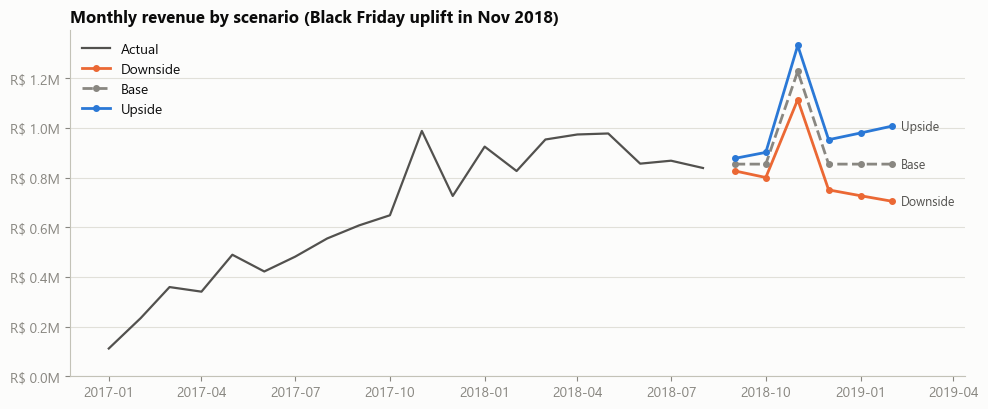

In [3]:
tot = proj.groupby(["scenario", "ds"], as_index=False)["revenue"].sum()
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(hist["ds"], hist["revenue"], color=INK2, lw=1.6, label="Actual")
for s in cfg.SCENARIOS:
    d = tot[tot["scenario"] == s]
    ax.plot(d["ds"], d["revenue"], color=SCN_COLOR[s], ls="--" if s == "Base" else "-", marker="o", ms=4, label=s)
    ax.text(d["ds"].iloc[-1] + pd.Timedelta(days=8), d["revenue"].iloc[-1], s, color=INK2, va="center", fontsize=9)
ax.set_xlim(right=tot["ds"].max() + pd.Timedelta(days=70))
ax.yaxis.set_major_formatter(brl_m); ax.set_ylim(bottom=0)
ax.set_title("Monthly revenue by scenario (Black Friday uplift in Nov 2018)"); ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(IMG / "04_scenarios.png", dpi=150); plt.show()

In [4]:
t = summ.pivot(index="market", columns="scenario", values="six_months").loc[cfg.MARKETS + ["Total"], cfg.SCENARIOS]
q = summ[summ["market"] == "Total"].set_index("scenario").loc[cfg.SCENARIOS, ["plan_q1", "plan_q2", "six_months"]]
last6 = hist.tail(6)["revenue"].sum()
q["vs Mar-Aug 2018 actual"] = (q["six_months"] / last6 - 1).map("{:+.1%}".format)
q[["plan_q1", "plan_q2", "six_months"]] = (q[["plan_q1", "plan_q2", "six_months"]] / 1e6).round(2)
print("Total, R$M (Plan Q1 = Sep-Nov 2018, Plan Q2 = Dec 2018-Feb 2019)")
display(q)
print("6-month revenue by market, R$k")
(t / 1e3).round(0)

Total, R$M (Plan Q1 = Sep-Nov 2018, Plan Q2 = Dec 2018-Feb 2019)


,plan_q1,plan_q2,six_months,vs Mar-Aug 2018 actual
scenario,,,,
Downside,2.74,2.18,4.92,-10.0%
Base,2.94,2.56,5.50,+0.6%
Upside,3.11,2.94,6.05,+10.7%


6-month revenue by market, R$k


scenario,Downside,Base,Upside
market,,,
SP,2121.0,2253.0,2634.0
RJ,525.0,624.0,610.0
MG,533.0,630.0,646.0
South,623.0,747.0,826.0
Rest of Brazil,1121.0,1245.0,1334.0
Total,4923.0,5499.0,6050.0


## 3. Where is extra growth worth most?

There is no cost or marketing data, so this is **revenue sensitivity, not return on investment**. Two views:
how much one extra point of monthly customer growth is worth in each market, and each market's momentum.

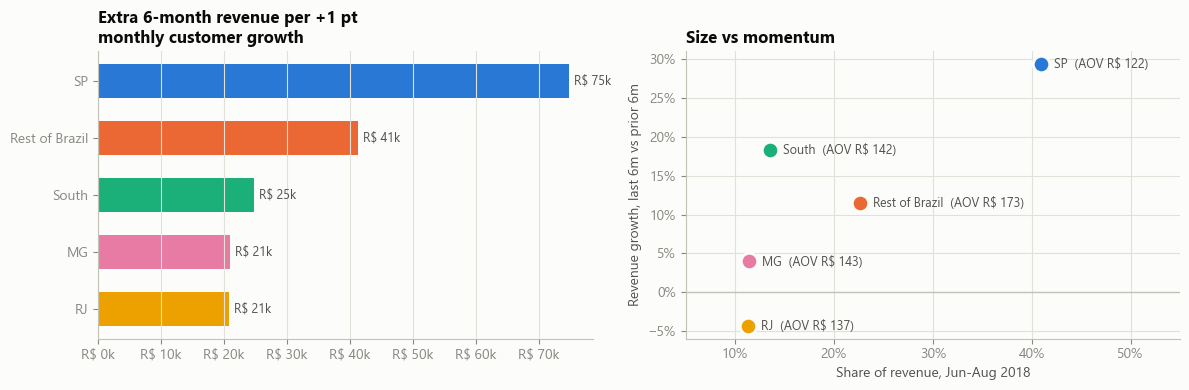

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = msc["extra_6m_revenue_per_1pt_customers"].sort_values().index
ax = axes[0]
ax.barh(order, msc.loc[order, "extra_6m_revenue_per_1pt_customers"], color=[MKT_COLOR[m] for m in order], height=0.6)
for i, m in enumerate(order):
    v = msc.loc[m, "extra_6m_revenue_per_1pt_customers"]
    ax.text(v + 800, i, f"R$ {v/1e3:.0f}k", va="center", color=INK2, fontsize=9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"R$ {v/1e3:.0f}k"))
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Extra 6-month revenue per +1 pt\nmonthly customer growth")

ax = axes[1]
x, y = msc["revenue_share"], msc["revenue_growth_last6m"]
ax.axhline(0, color=AXIS, lw=1)
for m in cfg.MARKETS:
    ax.scatter(x[m], y[m], s=140, color=MKT_COLOR[m], edgecolor=SURF, linewidth=2, zorder=3)
    ax.annotate(f"{m}  (AOV R$ {msc.loc[m, 'aov']:.0f})", (x[m], y[m]), xytext=(9, -3),
                textcoords="offset points", color=INK2, fontsize=9)
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlim(0.05, 0.55); ax.grid(axis="x", visible=True)
ax.set_xlabel("Share of revenue, Jun-Aug 2018"); ax.set_ylabel("Revenue growth, last 6m vs prior 6m")
ax.set_title("Size vs momentum")
fig.tight_layout(); fig.savefig(IMG / "04_market_scorecard.png", dpi=150); plt.show()

In [6]:
show = msc.copy()
pcols = ["revenue_share", "revenue_growth_yoy", "revenue_growth_last6m", "customers_growth_last6m",
         "aov_growth_last6m", "customers_growth_last3m", "share_of_recent_growth"]
show[pcols] = (show[pcols] * 100).round(1)
show[["baseline_revenue_month", "extra_6m_revenue_per_1pt_customers"]] = (
    show[["baseline_revenue_month", "extra_6m_revenue_per_1pt_customers"]] / 1e3).round(1)
show["aov"] = show["aov"].round(1)
show.rename(columns={"baseline_revenue_month": "revenue/month (R$k)",
                     "extra_6m_revenue_per_1pt_customers": "R$k per +1 pt customers"})

,revenue_share,revenue/month (R$k),aov,revenue_growth_yoy,revenue_growth_last6m,customers_growth_last6m,aov_growth_last6m,customers_growth_last3m,share_of_recent_growth,R$k per +1 pt customers
market,,,,,,,,,,
SP,41.0,350.0,121.8,170.5,29.4,26.8,2.9,-5.1,68.2,74.7
RJ,11.4,97.0,136.8,104.5,-4.3,-2.0,-1.8,-14.1,-3.9,20.7
MG,11.5,97.8,142.6,153.1,4.0,4.8,-0.3,-13.7,3.2,20.9
South,13.6,116.0,141.9,129.7,18.4,6.9,11.3,-14.8,16.3,24.8
Rest of Brazil,22.7,193.4,173.0,120.1,11.5,2.3,10.0,-8.8,16.2,41.3


## 4. Categories

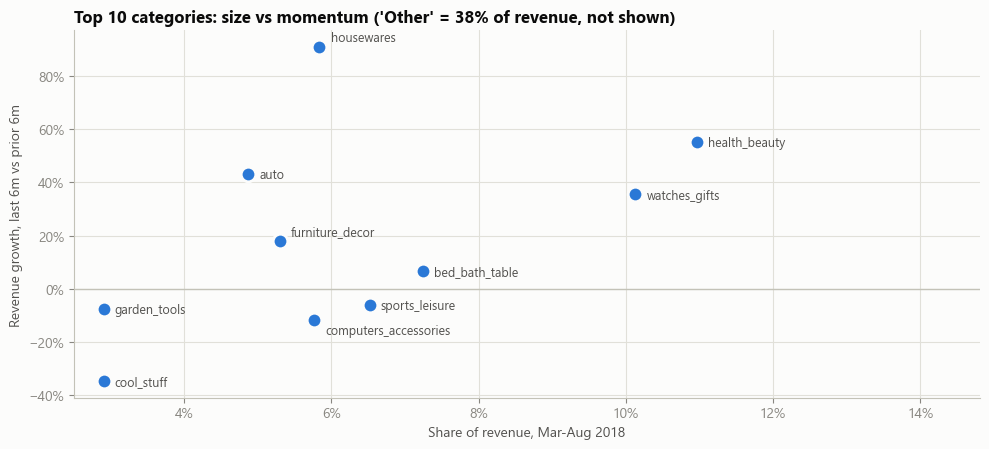

In [7]:
c = csc.drop(index=cfg.OTHER_CATEGORY)
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.axhline(0, color=AXIS, lw=1)
ax.scatter(c["revenue_share_last6m"], c["revenue_growth_last6m"], s=110, color=SERIES[0],
           edgecolor=SURF, linewidth=2, zorder=3)
offsets = {k: (8, -3) for k in c.index}
offsets.update({"housewares": (8, 4), "computers_accessories": (8, -10), "furniture_decor": (8, 4)})
for k in c.index:
    ax.annotate(k, (c.loc[k, "revenue_share_last6m"], c.loc[k, "revenue_growth_last6m"]),
                xytext=offsets[k], textcoords="offset points", color=INK2, fontsize=9)
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct); ax.grid(axis="x", visible=True)
ax.set_xlim(right=c["revenue_share_last6m"].max() * 1.35)
ax.set_xlabel("Share of revenue, Mar-Aug 2018"); ax.set_ylabel("Revenue growth, last 6m vs prior 6m")
ax.set_title(f"Top {cfg.TOP_N_CATEGORIES} categories: size vs momentum ('Other' = "
             f"{csc.loc[cfg.OTHER_CATEGORY, 'revenue_share_last6m']:.0%} of revenue, not shown)")
fig.tight_layout(); fig.savefig(IMG / "04_category_scorecard.png", dpi=150); plt.show()

In [8]:
cs = csc.copy()
pc = ["revenue_share_last6m", "revenue_growth_yoy", "revenue_growth_last6m", "aov_growth_last6m"]
cs[pc] = (cs[pc] * 100).round(1)
cs["revenue_last6m"] = (cs["revenue_last6m"] / 1e3).round(0)
cs["aov_last6m"] = cs["aov_last6m"].round(1)
cs.rename(columns={"revenue_last6m": "revenue_last6m (R$k)"})

,revenue_share_last6m,revenue_last6m (R$k),aov_last6m,revenue_growth_yoy,revenue_growth_last6m,aov_growth_last6m
category,,,,,,
Other,37.5,2051.0,140.3,144.0,13.9,6.5
health_beauty,11.0,600.0,144.6,210.3,55.3,4.1
watches_gifts,10.1,554.0,198.3,242.0,35.4,-7.0
bed_bath_table,7.2,397.0,111.2,109.2,6.6,3.3
sports_leisure,6.5,356.0,126.1,138.6,-6.1,-2.2
housewares,5.8,319.0,118.3,207.2,91.0,16.3
computers_accessories,5.8,316.0,121.1,131.2,-11.8,-15.1
furniture_decor,5.3,290.0,123.7,123.4,18.0,9.7
auto,4.9,266.0,141.9,174.1,43.1,-4.9


## 5. What this means

In [9]:
s = summ[summ["market"] == "Total"].set_index("scenario")["six_months"]
m = msc
print(f"- Plan range for Sep 2018 - Feb 2019: R$ {s['Downside']/1e6:.2f}M (downside) / {s['Base']/1e6:.2f}M (base) / "
      f"{s['Upside']/1e6:.2f}M (upside), all with the Black Friday uplift.")
print(f"- The downside is not a stress test: it only assumes the Jun-Aug customer decline continues. "
      f"It is R$ {(s['Base']-s['Downside'])/1e6:.2f}M below base.")
print(f"- SP is the largest lever: +1 pt monthly customer growth there is worth R$ {m.loc['SP','extra_6m_revenue_per_1pt_customers']/1e3:.0f}k, "
      f"{m.loc['SP','extra_6m_revenue_per_1pt_customers']/m.loc['RJ','extra_6m_revenue_per_1pt_customers']:.1f}x RJ. "
      f"SP also delivered {m.loc['SP','share_of_recent_growth']:.0%} of recent growth.")
print(f"- South and Rest of Brazil grew through AOV (+{m.loc['South','aov_growth_last6m']:.0%} and "
      f"+{m.loc['Rest of Brazil','aov_growth_last6m']:.0%}); Rest of Brazil has the highest AOV (R$ {m.loc['Rest of Brazil','aov']:.0f}).")
print(f"- RJ is shrinking ({m.loc['RJ','revenue_growth_last6m']:+.1%} last 6m) and MG is flat ({m.loc['MG','revenue_growth_last6m']:+.1%}).")
rj = summ[summ["market"] == "RJ"].set_index("scenario")["six_months"]
print(f"  Because presets follow each market's own trend, RJ's Upside (R$ {rj['Upside']/1e3:.0f}k) is below its Base "
      f"(R$ {rj['Base']/1e3:.0f}k): its momentum is negative.")
top = csc.drop(index=cfg.OTHER_CATEGORY).sort_values("revenue_growth_last6m", ascending=False)
print(f"- Categories with momentum: " + ", ".join(f"{k} ({v:+.0%})" for k, v in top['revenue_growth_last6m'].head(3).items())
      + "; declining: " + ", ".join(f"{k} ({v:+.0%})" for k, v in top['revenue_growth_last6m'].tail(3).items()) + ".")
print("- Recommendations and caveats are written up in Stage 5 (decision memo).")

- Plan range for Sep 2018 - Feb 2019: R$ 4.92M (downside) / 5.50M (base) / 6.05M (upside), all with the Black Friday uplift.
- The downside is not a stress test: it only assumes the Jun-Aug customer decline continues. It is R$ 0.58M below base.
- SP is the largest lever: +1 pt monthly customer growth there is worth R$ 75k, 3.6x RJ. SP also delivered 68% of recent growth.
- South and Rest of Brazil grew through AOV (+11% and +10%); Rest of Brazil has the highest AOV (R$ 173).
- RJ is shrinking (-4.3% last 6m) and MG is flat (+4.0%).
  Because presets follow each market's own trend, RJ's Upside (R$ 610k) is below its Base (R$ 624k): its momentum is negative.
- Categories with momentum: housewares (+91%), health_beauty (+55%), auto (+43%); declining: garden_tools (-8%), computers_accessories (-12%), cool_stuff (-35%).
- Recommendations and caveats are written up in Stage 5 (decision memo).
